In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("supermarket_sales_case_study.csv")
print(df.shape)
df.head()

(8631, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,852-73-6802,A,Yangon,Normal,Female,Health and beauty,52.24,4,10.4480,219.4080,1/1/2023,12:46,Ewallet,208.96,4.761905,10.4480,7.1
1,845-69-3430,A,Yangon,Member,Male,Sports and travel,50.54,6,15.1620,318.4020,1/1/2023,17:55,Ewallet,303.24,4.761905,15.1620,8.4
2,307-57-9082,B,Mandalay,Member,Male,Fashion accessories,69.86,4,13.9720,293.4120,1/1/2023,12:40,Credit card,279.44,4.761905,13.9720,8.3
3,453-35-6332,B,Mandalay,Member,Female,Home and lifestyle,52.63,5,13.1575,276.3075,1/1/2023,17:20,Ewallet,263.15,4.761905,13.1575,7.1
4,365-74-6230,B,Mandalay,Normal,Male,Sports and travel,42.97,4,8.5940,180.4740,1/1/2023,17:36,Cash,171.88,4.761905,8.5940,5.3


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("supermarket_sales_case_study.csv")
audit = {}
audit["0 loaded"] = len(df)

print(df.shape)
print(df.dtypes)
df.head()

(8631, 17)
Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,852-73-6802,A,Yangon,Normal,Female,Health and beauty,52.24,4,10.4480,219.4080,1/1/2023,12:46,Ewallet,208.96,4.761905,10.4480,7.1
1,845-69-3430,A,Yangon,Member,Male,Sports and travel,50.54,6,15.1620,318.4020,1/1/2023,17:55,Ewallet,303.24,4.761905,15.1620,8.4
2,307-57-9082,B,Mandalay,Member,Male,Fashion accessories,69.86,4,13.9720,293.4120,1/1/2023,12:40,Credit card,279.44,4.761905,13.9720,8.3
3,453-35-6332,B,Mandalay,Member,Female,Home and lifestyle,52.63,5,13.1575,276.3075,1/1/2023,17:20,Ewallet,263.15,4.761905,13.1575,7.1
4,365-74-6230,B,Mandalay,Normal,Male,Sports and travel,42.97,4,8.5940,180.4740,1/1/2023,17:36,Cash,171.88,4.761905,8.5940,5.3


In [5]:
print(df.isna().sum())
print("exact duplicates:", df.duplicated().sum())
print("repeated Invoice IDs:", df["Invoice ID"].duplicated().sum())
print(df["Gender"].value_counts(dropna=False))
print(df["Payment"].value_counts(dropna=False))

Invoice ID                  0
Branch                      0
City                        0
Customer type              64
Gender                      0
Product line                0
Unit price                  0
Quantity                    0
Tax 5%                      0
Total                       0
Date                       17
Time                        0
Payment                     0
cogs                        0
gross margin percentage     0
gross income                0
Rating                     88
dtype: int64
exact duplicates: 30
repeated Invoice IDs: 55
Gender
Female     4534
Male       4024
MALE         22
 Female      18
female       17
male         16
Name: count, dtype: int64
Payment
Ewallet         3217
Cash            2799
Credit card     2566
 Credit card      15
ewallet           13
cash              12
EWALLET            9
Name: count, dtype: int64


In [6]:
df = df.drop_duplicates()
audit["3 exact duplicates dropped"] = len(df)
print(len(df), "rows bachi")

8601 rows bachi


In [8]:
print("conflicts pehle:", df["Invoice ID"].duplicated().sum())
df = df.drop_duplicates(subset="Invoice ID" , keep="last")
audit["4 conflictingIDs resolved"] = len(df)
print(len(df), "rows bachi")

conflicts pehle: 25
8576 rows bachi


In [10]:
gender_map = {"male": "Male", "female": "Female"}
payment_map = {"cash": "Cash", "credit card": "Credit card", "ewallet": "Ewallet"}
df["Gender"] = df["Gender"].str.strip().str.lower().map(gender_map)
df["Payment"] = df["Payment"].str.strip().str.lower().map(payment_map)
audit["5 text standardised"] = len(df)
print(df["Gender"].value_counts(dropna=False))
print(df["Payment"].value_counts(dropna=False))

Gender
NaN    8576
Name: count, dtype: int64
Payment
Ewallet        3215
Cash           2796
Credit card    2565
Name: count, dtype: int64


In [11]:
df = pd.read_csv("supermarket_sales_case_study.csv")
audit = {"0 loaded": len(df)}

df = df.drop_duplicates()
audit["3 exact duplicates dropped"] = len(df)

df = df.drop_duplicates(subset="Invoice ID", keep="last")
audit["4 conflicting IDs resolved"] = len(df)

gender_map  = {"male": "Male", "female": "Female"}
payment_map = {"cash": "Cash", "credit card": "Credit card", "ewallet": "Ewallet"}
df["Gender"]  = df["Gender"].str.strip().str.lower().map(gender_map)
df["Payment"] = df["Payment"].str.strip().str.lower().map(payment_map)
audit["5 text standardised"] = len(df)

print(len(df))
print(df["Gender"].value_counts(dropna=False))
print(df["Payment"].value_counts(dropna=False))

8576
Gender
Female    4539
Male      4037
Name: count, dtype: int64
Payment
Ewallet        3215
Cash           2796
Credit card    2565
Name: count, dtype: int64


In [12]:
print("negative qty pehle:", (df["Quantity"] < 0).sum())  
df["Quantity"] = df["Quantity"].abs()
audit["6 negative qty fixed"] = len(df)
print("negative qty baad mein:", (df["Quantity"] < 0).sum()) 

negative qty pehle: 57
negative qty baad mein: 0


In [13]:
d1 = pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce")
d2 = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
df["Date"] = d1.fillna(d2)     
print("parse hui:", df["Date"].notna().sum())
print("missing:", df["Date"].isna().sum())
audit["7 dates parsed"] = len(df)

parse hui: 8514
missing: 62


In [14]:
calc_total = df["Quantity"] * df["Unit price"] * 1.05
mask = (df["Total"] - calc_total).abs() > 0.50
print("galat Total:", mask.sum())              
df.loc[mask, "Total"] = calc_total[mask]
audit["8 total checked"] = len(df)
print((df["Total"] - calc_total).abs().max())   

galat Total: 62
2.2737367544323206e-13


In [15]:
print(df.isna().sum()[lambda s: s > 0])            
median_rating = df["Rating"].median()
df["Customer type"] = df["Customer type"].fillna("Unknown")
df["Rating"] = df["Rating"].fillna(median_rating)
df = df.dropna(subset=["Date"])
audit["9 missing handled"] = len(df)
print("median rating:", median_rating)              
print(len(df), "rows,", df.isna().sum().sum(), "missing bacha")   

Customer type    64
Date             62
Rating           85
dtype: int64
median rating: 7.1
8514 rows, 0 missing bacha


In [16]:
trail = pd.DataFrame({"step": list(audit.keys()), "rows_after": list(audit.values())})
trail["rows_removed"] = trail["rows_after"].shift(1) - trail["rows_after"]
trail["rows_removed"] = trail["rows_removed"].fillna(0).astype(int)
trail

,step,rows_after,rows_removed
0,0 loaded,8631,0
1,3 exact duplicates dropped,8601,30
2,4 conflicting IDs resolved,8576,25
3,5 text standardised,8576,0
4,6 negative qty fixed,8576,0
5,7 dates parsed,8576,0
6,8 total checked,8576,0
7,9 missing handled,8514,62


In [17]:
df["Year"] = df["Date"].dt.year
df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)   
df["Day of week"] = df["Date"].dt.day_name()                 
df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M").dt.hour
print(df["Year"].value_counts())
print(sorted(df["Quarter"].unique()))
print(df["Hour"].value_counts().sort_index())

Year
2023    4311
2024    4203
Name: count, dtype: int64
['2023Q1', '2023Q2', '2023Q3', '2023Q4', '2024Q1', '2024Q2', '2024Q3', '2024Q4']
Hour
10     391
11     663
12    1098
13     903
14     670
15     658
16     722
17    1003
18    1165
19     846
20     395
Name: count, dtype: int64


In [18]:
df["Bucket"] = pd.cut(df["Hour"], bins=[10, 13, 17, 21], right=False,
                      labels=["Morning", "Afternoon", "Evening"])
print("bucket missing:", df["Bucket"].isna().sum())     # 0

hours_in_bucket = {"Morning": 3, "Afternoon": 4, "Evening": 4}
counts = df["Bucket"].value_counts()
tph = (counts / pd.Series(hours_in_bucket)).round(1)    # transactions per hour
print(counts)
print(tph)

bucket missing: 0
Bucket
Evening      3409
Afternoon    2953
Morning      2152
Name: count, dtype: int64
Bucket
Afternoon    738.2
Evening      852.2
Morning      717.3
dtype: float64


In [19]:
rev = (df.groupby(["Branch", "Quarter"], as_index=False)["Total"].sum()
         .rename(columns={"Total": "Revenue"}))
targets = pd.DataFrame({"Branch": ["A", "B", "C"], "Target": [100000] * 3})
rev = rev.merge(targets, on="Branch", how="left")
rev["Variance"]    = rev["Revenue"] - rev["Target"]
rev["% of target"] = (rev["Revenue"] / rev["Target"] * 100).round(1)
rev["Hit"]         = rev["Revenue"] >= rev["Target"]
print(rev.shape)                      
rev

(24, 7)


,Branch,Quarter,Revenue,Target,Variance,% of target,Hit
0,A,2023Q1,102248.7795,100000,2248.7795,102.2,True
1,A,2023Q2,90064.1595,100000,-9935.8405,90.1,False
2,A,2023Q3,90878.3400,100000,-9121.6600,90.9,False
3,A,2023Q4,129821.3280,100000,29821.3280,129.8,True
4,A,2024Q1,112450.6425,100000,12450.6425,112.5,True
5,A,2024Q2,98243.2815,100000,-1756.7185,98.2,False
6,A,2024Q3,89175.6705,100000,-10824.3295,89.2,False
7,A,2024Q4,117506.8125,100000,17506.8125,117.5,True
8,B,2023Q1,96366.0075,100000,-3633.9925,96.4,False
9,B,2023Q2,91993.3245,100000,-8006.6755,92.0,False


In [20]:
summary = rev.groupby("Branch").agg(
    avg_quarterly_revenue=("Revenue", "mean"),
    quarters_hit=("Hit", "sum"),
).round(0)
best  = rev.loc[rev.groupby("Branch")["Revenue"].idxmax()].set_index("Branch")["Quarter"]
worst = rev.loc[rev.groupby("Branch")["Revenue"].idxmin()].set_index("Branch")["Quarter"]
summary["best_quarter"]  = best
summary["worst_quarter"] = worst
yearly = df.pivot_table(index="Branch", columns="Year", values="Total", aggfunc="sum")
summary["YoY growth %"] = ((yearly[2024] / yearly[2023] - 1) * 100).round(1)

summary

,avg_quarterly_revenue,quarters_hit,best_quarter,worst_quarter,YoY growth %
Branch,,,,,
A,103799.0,4,2023Q4,2024Q3,1.1
B,93168.0,2,2024Q4,2024Q2,-5.3
C,103297.0,4,2024Q4,2023Q2,8.4


Matplotlib is building the font cache; this may take a moment.


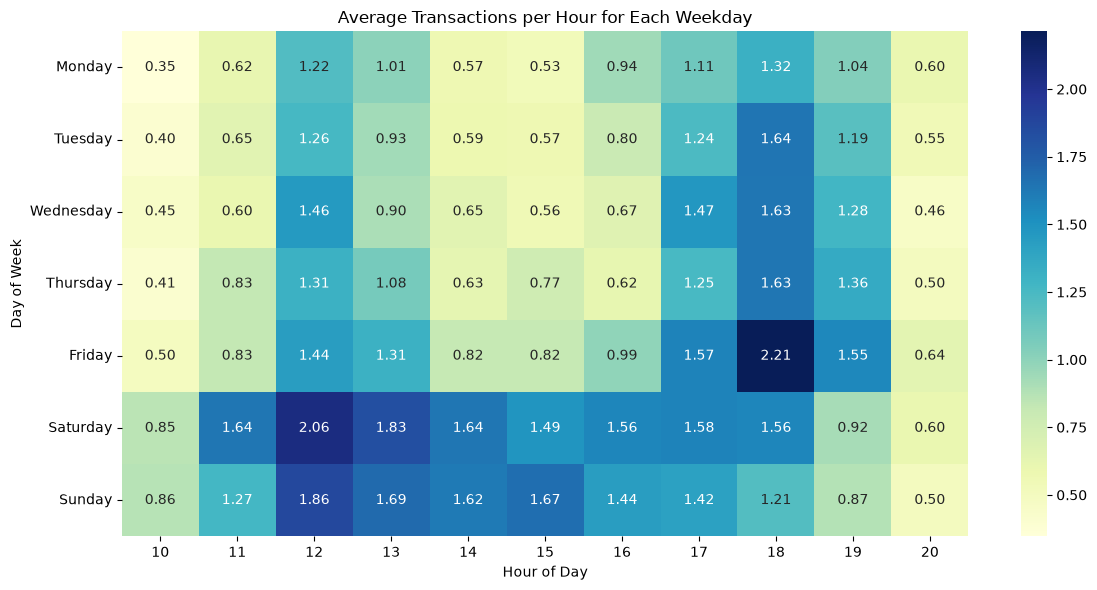

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('supermarket_sales_case_study.csv')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])

df['Weekday'] = df['Date'].dt.day_name()
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M', errors='coerce').dt.hour

weekday_counts = df.groupby('Weekday')['Date'].nunique()
hourly_weekday_tx = (
    df.groupby(['Weekday', 'Hour'])['Invoice ID'].count().unstack(fill_value=0)
)
hourly_weekday_avg = hourly_weekday_tx.div(weekday_counts, axis=0)

days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
hourly_weekday_avg = hourly_weekday_avg.reindex(days_order)

plt.figure(figsize=(12, 6))
sns.heatmap(hourly_weekday_avg, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Average Transactions per Hour for Each Weekday')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

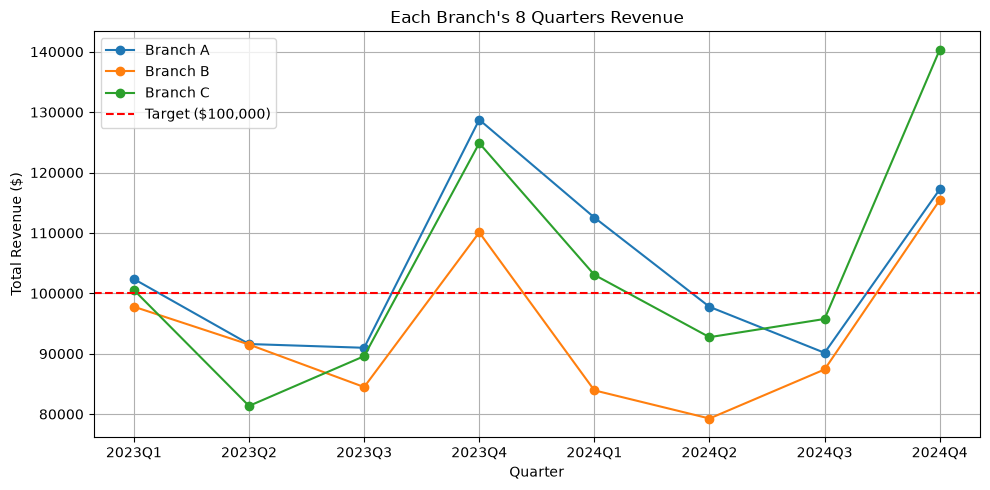

In [24]:
df['Quarter'] = df['Date'].dt.to_period('Q')
quarterly_sales = df.groupby(['Quarter', 'Branch'])['Total'].sum().unstack()

# Plot line chart
plt.figure(figsize=(10, 5))
for branch in quarterly_sales.columns:
  plt.plot(
      quarterly_sales.index.astype(str),
      quarterly_sales[branch],
      marker='o',
      label=f'Branch {branch}',
  )

plt.axhline(
    y=100000,
    color='r',
    linestyle='--',
    label='Target ($100,000)',
)

plt.title("Each Branch's 8 Quarters Revenue")
plt.xlabel('Quarter')
plt.ylabel('Total Revenue ($)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Clean data export to CSV
df.to_csv('cleaned_supermarket_sales.csv', index=False)